In [20]:
import time
import random
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import tensorflow as tf
import shutil
import seaborn as sns
import imagehash
from pathlib import Path
from tensorflow.keras import layers, models, regularizers, callbacks, optimizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix,  roc_curve
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications import MobileNetV2


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.22.0-rc0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [21]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

In [22]:
dataset_path = Path("./PlantVillage")

subdirs = sorted([
    d for d in dataset_path.iterdir()
    if d.is_dir() and d.name != "PlantVillage"
])

print(f"Найдено папок классов: {len(subdirs)}")
for d in subdirs:
    print(f"  - {d.name}")

Найдено папок классов: 15
  - Pepper__bell___Bacterial_spot
  - Pepper__bell___healthy
  - Potato___Early_blight
  - Potato___Late_blight
  - Potato___healthy
  - Tomato_Bacterial_spot
  - Tomato_Early_blight
  - Tomato_Late_blight
  - Tomato_Leaf_Mold
  - Tomato_Septoria_leaf_spot
  - Tomato_Spider_mites_Two_spotted_spider_mite
  - Tomato__Target_Spot
  - Tomato__Tomato_YellowLeaf__Curl_Virus
  - Tomato__Tomato_mosaic_virus
  - Tomato_healthy


In [23]:
CLASS_NAMES = {0: "Tomato", 1: "Potato", 2: "Pepper"}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def map_folder_to_class(folder_name: str):
    name_lower = folder_name.lower()
    if name_lower.startswith("tomato"):
        return 0, "Tomato"
    elif name_lower.startswith("potato"):
        return 1, "Potato"
    elif name_lower.startswith("pepper"):
        return 2, "Pepper"
    return None, None

records = []
corrupted_files = []

for folder in subdirs:
    class_id, class_name = map_folder_to_class(folder.name)
    if class_id is None:
        continue

    for file_path in sorted(folder.iterdir()):
        if not file_path.is_file():
            continue
        if file_path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        # Проверка целостности изображения, формата, разрешения и MD5-хэша (для поиска точных дубликатов)
        try:
            with Image.open(file_path) as img:
                img.verify()  

            with Image.open(file_path) as img:
                width, height = img.size
                mode = img.mode
                img_format = img.format
                img.load()
                phash = str(imagehash.phash(img.convert("RGB")))


            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            records.append({
                "filepath": str(file_path),
                "filename": file_path.name,
                "subfolder": folder.name,
                "class_id": class_id,
                "class_name": class_name,
                "width": width,
                "height": height,
                "mode": mode,
                "format": img_format,
                "phash": phash,
                "md5": file_hash
            })
        except (UnidentifiedImageError, OSError, Exception) as e:
            corrupted_files.append((str(file_path), str(e)))

df = pd.DataFrame(records)

print("=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===")
print(f"Успешно проверено изображений: {len(df)}")
print(f"Повреждённых (битых) файлов: {len(corrupted_files)}")
if corrupted_files:
    print("Примеры битых файлов:", corrupted_files[:5])

print("Уникальные размеры изображений (W x H):")
print(df.groupby(["width", "height"]).size())


n_dups = df["md5"].duplicated().sum()
print(f"\nНайдено точных дубликатов файлов (MD5): {n_dups}")

# Проверка одинаковых файлов с разными метками
conflicts = df.groupby("md5")["class_id"].nunique()
conflicts = conflicts[conflicts > 1]

print("Конфликтующих меток:", len(conflicts))

assert conflicts.empty, "Обнаружены конфликтующие метки!"

=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===
Успешно проверено изображений: 20638
Повреждённых (битых) файлов: 0
Уникальные размеры изображений (W x H):
width  height
256    256       20638
dtype: int64

Найдено точных дубликатов файлов (MD5): 14
Конфликтующих меток: 0


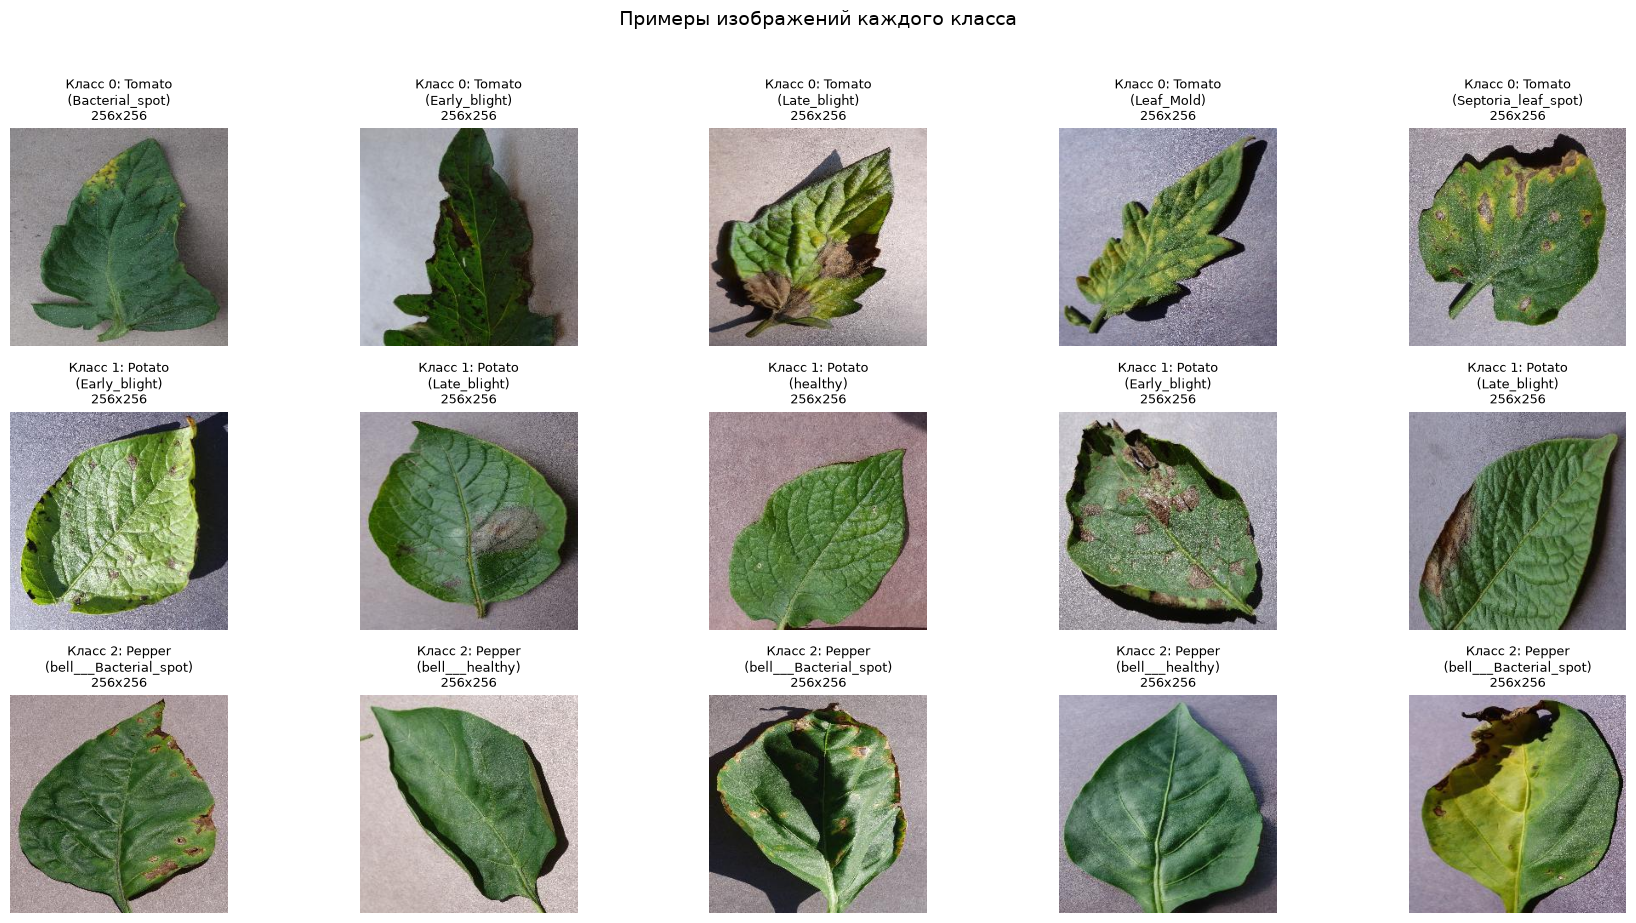

In [24]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(18, 9))

for row_idx, (class_id, class_name) in enumerate(CLASS_NAMES.items()):
    class_df = df[df["class_id"] == class_id]
    
    # Выбираем примеры из разных подклассов, если их несколько
    unique_subs = class_df["subfolder"].unique()
    sampled_rows = []
    for i in range(5):
        sub = unique_subs[i % len(unique_subs)]
        sample = class_df[class_df["subfolder"] == sub].sample(1, random_state=SEED + i)
        sampled_rows.append(sample.iloc[0])
    
    for col_idx, row in enumerate(sampled_rows):
        ax = axes[row_idx, col_idx]
        with Image.open(row["filepath"]) as img:
            ax.imshow(img)
        
        sub_short = row["subfolder"].replace(f"{class_name}___", "").replace(f"{class_name}__", "").replace(f"{class_name}_", "")
        ax.set_title(
            f"Класс {class_id}: {class_name}\n({sub_short})\n{row['width']}x{row['height']}",
            fontsize=9
        )
        ax.axis("off")

plt.suptitle("Примеры изображений каждого класса", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [25]:
print("\n=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===")
class_counts = df.groupby(["class_id", "class_name"]).size().reset_index(name="count")
class_counts["percent"] = (class_counts["count"] / len(df) * 100).round(2)
print(class_counts.to_string(index=False))

print("\n=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===")
sub_counts = df.groupby(["class_name", "subfolder"]).size().reset_index(name="count")
print(sub_counts.to_string(index=False))


=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===
 class_id class_name  count  percent
        0     Tomato  16011    77.58
        1     Potato   2152    10.43
        2     Pepper   2475    11.99

=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===
class_name                                   subfolder  count
    Pepper               Pepper__bell___Bacterial_spot    997
    Pepper                      Pepper__bell___healthy   1478
    Potato                       Potato___Early_blight   1000
    Potato                        Potato___Late_blight   1000
    Potato                            Potato___healthy    152
    Tomato                       Tomato_Bacterial_spot   2127
    Tomato                         Tomato_Early_blight   1000
    Tomato                          Tomato_Late_blight   1909
    Tomato                            Tomato_Leaf_Mold    952
    Tomato                   Tomato_Septoria_leaf_spot   1771
    Tomato Tomato_Spider_mites_Two_spotted_spider_mite   1676
    

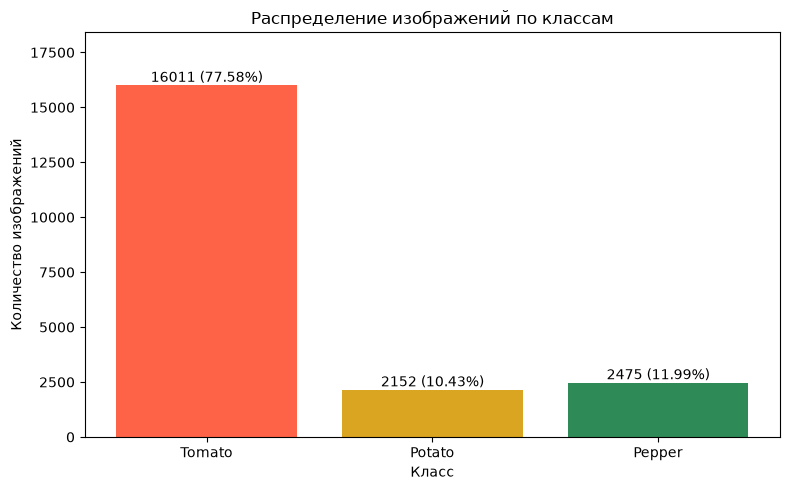

In [26]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts["class_name"],
    class_counts["count"],
    color=["tomato", "goldenrod", "seagreen"]
)

for bar, count, percent in zip(
    bars,
    class_counts["count"],
    class_counts["percent"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} ({percent:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Распределение изображений по классам")
plt.xlabel("Класс")
plt.ylabel("Количество изображений")
plt.ylim(0, class_counts["count"].max() * 1.15)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [27]:
ARTIFACTS_DIR = Path("./artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

n_before = len(df)
df_clean = df.drop_duplicates(subset=["md5"]).reset_index(drop=True)
n_removed = n_before - len(df_clean)
print(f"Удалено точных дубликатов (MD5): {n_removed}. Осталось уникальных изображений: {len(df_clean)}")

train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=SEED,
    stratify=df_clean["subfolder"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["subfolder"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert set(train_df["filepath"]).isdisjoint(set(val_df["filepath"])), "Утечка filepath: train и val!"
assert set(train_df["filepath"]).isdisjoint(set(test_df["filepath"])), "Утечка filepath: train и test!"
assert set(val_df["filepath"]).isdisjoint(set(test_df["filepath"])), "Утечка filepath: val и test!"
assert set(train_df["md5"]).isdisjoint(set(val_df["md5"])), "Утечка MD5: train и val!"
assert set(train_df["md5"]).isdisjoint(set(test_df["md5"])), "Утечка MD5: train и test!"
assert set(val_df["md5"]).isdisjoint(set(test_df["md5"])), "Утечка MD5: val и test!"
print("Проверка на утечку данных пройдена: пересечений по путям и MD5 нет.")

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

splits_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
splits_path = ARTIFACTS_DIR / "dataset_splits_var0.csv"
splits_df.to_csv(splits_path, index=False)
print(f"Разбиение сохранено в: {splits_path}")

Удалено точных дубликатов (MD5): 14. Осталось уникальных изображений: 20624
Проверка на утечку данных пройдена: пересечений по путям и MD5 нет.
Разбиение сохранено в: artifacts/dataset_splits_var0.csv


In [28]:
total = len(df_clean)
print("\n=== РАЗМЕРЫ ВЫБОРОК ===")
for name, part in [("Train (70%)", train_df), ("Val (15%)", val_df), ("Test (15%)", test_df)]:
    print(f"{name:<12}: {len(part):>6} изображений ({len(part) / total * 100:.2f}%)")

print("\n=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===")
summary = pd.DataFrame({
    "Train_cnt": train_df["class_name"].value_counts(),
    "Train_%": (train_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Val_cnt": val_df["class_name"].value_counts(),
    "Val_%": (val_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Test_cnt": test_df["class_name"].value_counts(),
    "Test_%": (test_df["class_name"].value_counts(normalize=True) * 100).round(2),
})
print(summary)

# Расчёт весов классов СТРОГО по обучающей выборке для борьбы с дисбалансом
# Для бинарной классификации (только классы 0: Tomato и 1: Potato)
train_bin_df = train_df[train_df["class_id"].isin([0, 1])].reset_index(drop=True)
bin_classes = np.array([0, 1])
bin_weights = compute_class_weight(
    class_weight="balanced",
    classes=bin_classes,
    y=train_bin_df["class_id"].values
)
CLASS_WEIGHTS_BINARY = dict(zip(bin_classes, bin_weights))

print("\nВеса классов для бинарной модели (по train):", {k: round(float(v), 4) for k, v in CLASS_WEIGHTS_BINARY.items()})


=== РАЗМЕРЫ ВЫБОРОК ===
Train (70%) :  14436 изображений (70.00%)
Val (15%)   :   3094 изображений (15.00%)
Test (15%)  :   3094 изображений (15.00%)

=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===
            Train_cnt  Train_%  Val_cnt  Val_%  Test_cnt  Test_%
class_name                                                      
Tomato          11197    77.56     2400  77.57      2400   77.57
Pepper           1733    12.00      371  11.99       371   11.99
Potato           1506    10.43      323  10.44       323   10.44

Веса классов для бинарной модели (по train): {np.int64(0): 0.5673, np.int64(1): 4.2175}


In [29]:
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU активирован с memory_growth: {gpus}")
    except RuntimeError as e:
        print(f"GPU уже инициализирован, memory_growth не изменён: {e}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 64  
AUTOTUNE = tf.data.AUTOTUNE

def create_tf_dataset(dataframe: pd.DataFrame, img_size: tuple = IMG_SIZE, batch_size: int = BATCH_SIZE, shuffle: bool = False, cache: bool = False, preprocess_fn=None, seed: int = SEED) -> tf.data.Dataset:

    filepaths = dataframe["filepath"].values
    labels = dataframe["class_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    def load_and_preprocess(path, label):
        img_bytes = tf.io.read_file(path)
        img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method=tf.image.ResizeMethod.BILINEAR)
        img = tf.cast(img, tf.float32)

        if preprocess_fn is not None:
            img = preprocess_fn(img)
        else:
            img = img / 255.0  # [0; 1] для собственной CNN

        img.set_shape([img_size[0], img_size[1], 3])
        return img, label

    # Декодирование и ресайз распараллеливаются по ядрам CPU
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache:
        ds = ds.cache()  # Храним готовые тензоры в ОЗУ

    if shuffle:
        # reshuffle_each_iteration=True заново перемешивает кэш на каждой эпохе
        ds = ds.shuffle(buffer_size=len(dataframe), seed=seed, reshuffle_each_iteration=True)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

# --- Формирование выборок для Этапа 3 (Бинарная CNN: классы 0 и 1) ---
val_bin_df = val_df[val_df["class_id"].isin([0, 1])].reset_index(drop=True)
test_bin_df = test_df[test_df["class_id"].isin([0, 1])].reset_index(drop=True)

train_ds_bin = create_tf_dataset(train_bin_df, shuffle=True, cache=True, preprocess_fn=None)
val_ds_bin = create_tf_dataset(val_bin_df, shuffle=False, cache=True, preprocess_fn=None)
test_ds_bin = create_tf_dataset(test_bin_df, shuffle=False, cache=False, preprocess_fn=None)

all_val_results = []
all_histories = {}

# Проверка формы и диапазона значений первого батча для собственной CNN
images_batch, labels_batch = next(iter(train_ds_bin))
print("\n=== ПРОВЕРКА БАТЧА ДЛЯ СОБСТВЕННОЙ CNN (БИНАРНАЯ) ===")
print("Форма тензора изображений:", images_batch.shape)
print("Тип данных:", images_batch.dtype)
print(f"Диапазон значений пикселей: [{images_batch.numpy().min():.3f}, {images_batch.numpy().max():.3f}]")
print("Метки в батче (уникальные):", np.unique(labels_batch.numpy()))
print(f"Размеры бинарных выборок -> train: {len(train_bin_df)}, val: {len(val_bin_df)}, test: {len(test_bin_df)}")

GPU уже инициализирован, memory_growth не изменён: Physical devices cannot be modified after being initialized

=== ПРОВЕРКА БАТЧА ДЛЯ СОБСТВЕННОЙ CNN (БИНАРНАЯ) ===
Форма тензора изображений: (64, 224, 224, 3)
Тип данных: <dtype: 'float32'>
Диапазон значений пикселей: [0.000, 0.995]
Метки в батче (уникальные): [0 1]
Размеры бинарных выборок -> train: 12703, val: 2723, test: 2723


Model: "CNN_1_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,761 (98.07 MB)

 Trainable params: 25,709,761 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


... (2 outputs left out)

I0000 00:00:1795844270.681846    1077 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.8547 - auc: 0.9224 - loss: 0.3737
Epoch 1: val_loss improved from None to 0.26688, saving model to artifacts/CNN-1_best.keras

Epoch 1: finished saving model to artifacts/CNN-1_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 33s 124ms/step - accuracy: 0.8547 - auc: 0.9224 - loss: 0.3737 - val_accuracy: 0.8909 - val_auc: 0.9737 - val_loss: 0.2669 - learning_rate: 0.0010
Epoch 2/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9085 - auc: 0.9696 - loss: 0.2219
Epoch 2: val_loss improved from 0.26688 to 0.19011, saving model to artifacts/CNN-1_best.keras

Epoch 2: finished saving model to artifacts/CNN-1_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 17s 86ms/step - accuracy: 0.9085 - auc: 0.9697 - loss: 0.2218 - val_accuracy: 0.9295 - val_auc: 0.9783 - val_loss: 0.1901 - learning_rate: 0.0010
Epoch 3/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9358 - auc: 0.9835 - loss: 0.1618
Epoch 3: val_loss did not improve from 0.19011

W0000 00:00:1795844346.548476    1077 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9733 - auc: 0.9969 - loss: 0.0646
Epoch 5: val_loss did not improve from 0.14049
199/199 ━━━━━━━━━━━━━━━━━━━━ 17s 83ms/step - accuracy: 0.9732 - auc: 0.9969 - loss: 0.0647 - val_accuracy: 0.9398 - val_auc: 0.9827 - val_loss: 0.1925 - learning_rate: 0.0010
Epoch 6/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9843 - auc: 0.9986 - loss: 0.0417
Epoch 6: val_loss improved from 0.14049 to 0.12417, saving model to artifacts/CNN-1_best.keras

Epoch 6: finished saving model to artifacts/CNN-1_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 17s 84ms/step - accuracy: 0.9843 - auc: 0.9986 - loss: 0.0419 - val_accuracy: 0.9600 - val_auc: 0.9836 - val_loss: 0.1242 - learning_rate: 0.0010
Epoch 7/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9848 - auc: 0.9990 - loss: 0.0368
Epoch 7: val_loss did not improve from 0.12417
199/199 ━━━━━━━━━━━━━━━━━━━━ 16s 81ms/step - accuracy: 0.9847 - auc: 0.9990 - loss: 0.0367 - val_accuracy: 

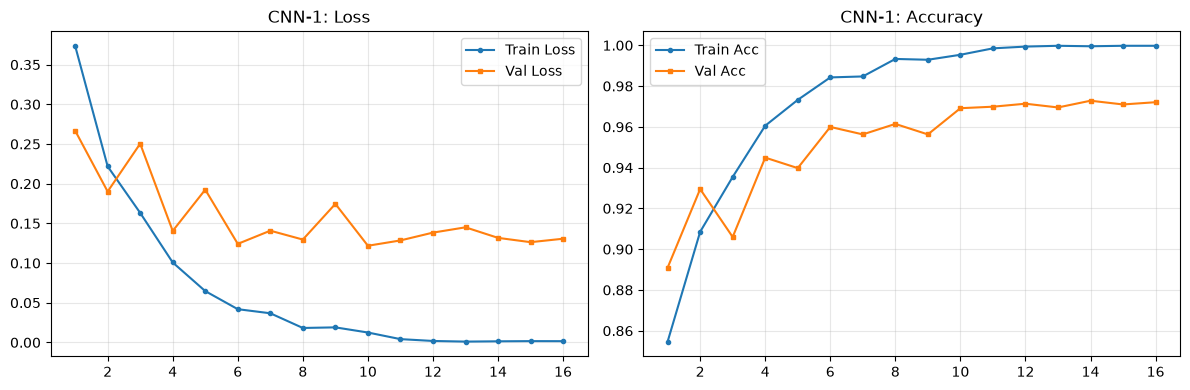


Результат CNN-1:
Эксперимент  Параметры                           Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761 2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001       16 (10)     279.1               0.9954   0.9692    0.1218         0.8632      0.8793  0.8712       0.9869


In [30]:
MAX_EPOCHS = 25
INPUT_SHAPE = (224, 224, 3)
# Общая функция запуска одного эксперимента с диагностикой 
def train_and_evaluate_val(model, exp_name: str, lr_init: float, opt_name: str, extra_info: dict):
    tf.keras.utils.set_random_seed(SEED)
    y_val_true = np.concatenate([y.numpy() for _, y in val_ds_bin], axis=0)

    ckpt_path = ARTIFACTS_DIR / f"{exp_name}_best.keras"
    cb_list = [
        callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=6, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
    ]

    t0 = time.perf_counter()
    history = model.fit(
        train_ds_bin,
        validation_data=val_ds_bin,
        epochs=MAX_EPOCHS,
        class_weight=CLASS_WEIGHTS_BINARY,
        callbacks=cb_list,
        verbose=1
    )
    elapsed = time.perf_counter() - t0

    hist = {k: [float(x) for x in v] for k, v in history.history.items()}
    with open(ARTIFACTS_DIR / f"{exp_name}_history.json", "w", encoding="utf-8") as f:
        json.dump(hist, f, indent=2)

    best_model = models.load_model(ckpt_path)
    val_loss = best_model.evaluate(val_ds_bin, verbose=0)[0]
    y_val_prob = best_model.predict(val_ds_bin, verbose=0).ravel()
    y_val_pred = (y_val_prob >= 0.5).astype(int)

    best_ep = int(np.argmin(hist["val_loss"])) + 1
    row = {
        "Эксперимент": exp_name,
        "Параметры": model.count_params(),
        **extra_info,
        "Оптимизатор": opt_name,
        "LR_init": lr_init,
        "Эпох (Лучшая)": f"{len(hist['loss'])} ({best_ep})",
        "Время, с": round(elapsed, 1),
        "Train Acc (best_ep)": round(hist["accuracy"][best_ep - 1], 4),
        "Val Acc": round(accuracy_score(y_val_true, y_val_pred), 4),
        "Val Loss": round(float(val_loss), 4),
        "Val Precision": round(precision_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val Recall": round(recall_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val F1": round(f1_score(y_val_true, y_val_pred, zero_division=0), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val_true, y_val_prob), 4),
    }

    # График обучения
    epochs_r = range(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_r, hist["loss"], label="Train Loss", marker="o", markersize=3)
    axes[0].plot(epochs_r, hist["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[0].set_title(f"{exp_name}: Loss")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs_r, hist["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[1].plot(epochs_r, hist["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[1].set_title(f"{exp_name}: Accuracy")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    del best_model
    tf.keras.backend.clear_session()
    gc.collect()
    return row, hist

# --- ШАГ 1: Базовая модель (CNN-1) ---
tf.keras.utils.set_random_seed(SEED)
cnn_1 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="CNN_1_Baseline")

cnn_1.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_1.summary()

res_1, hist_1 = train_and_evaluate_val(
    cnn_1, "CNN-1", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "2 Conv (32,64) + Flatten + Dense(128)", "Регуляризация": "Dropout 0.3"}
)
all_val_results.append(res_1)
all_histories["CNN-1"] = hist_1
print("\nРезультат CNN-1:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Анализ результатов CNN-1

* **Ловушка Accuracy vs F1 (`0.9640` vs `0.8533`):** Из-за дисбаланса (`Tomato` 88% / `Potato` 12%) константный прогноз дал бы 88% точности. Реальное качество на редком классе `Potato` отражает **F1 = 0.8533** (`Precision = 0.8261`, `Recall = 0.8824` — модель пропускает 11.8% картофеля и в 17.4% случаев путает с ним томаты). **Ориентир для отбора моделей:** `Val F1`, `Val Loss` и `Val ROC-AUC`.
* **Высокий Val ROC-AUC (`0.9874`):** Базовая 2-слойная сеть отлично разделяет классы по вероятностям, но при пороге `0.5` ошибается на граничных примерах (больных листьях). У датасета высокий потенциал.
* **Переобучение (`9 (3)` эпох и 25.7 млн параметров):** Лучший `Val Loss = 0.1023` достигнут уже на **3-й эпохе**, далее сработал `EarlyStopping`. Причина — слой `Flatten` раздул `Dense(128)` до **25.7 млн** параметров против ~19 тыс. в свертках (`2 Conv: 32, 64`). Вместо извлечения признаков сеть за 3 эпохи запомнила выборку.


Исходя из результатов CNN-1, у нас есть **две конкретные проблемы**:
    1. Раздутая «голова» (Flatten → 25.7 млн параметров) вызывает быстрое переобучение на 9-й эпохе.
    2. Слишком мелкая свёрточная часть (2 блока → обзор всего 10×10 пикселей) не даёт увидеть форму всего листа, из-за чего `Val F1` пока лишь 0.8533.

Model: "CNN_2_Deep_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6611 - auc: 0.7638 - loss: 0.5719
Epoch 1: val_loss improved from None to 0.25022, saving model to artifacts/CNN-2_best.keras

Epoch 1: finished saving model to artifacts/CNN-2_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 27s 118ms/step - accuracy: 0.6611 - auc: 0.7638 - loss: 0.5719 - val_accuracy: 0.9181 - val_auc: 0.9083 - val_loss: 0.2502 - learning_rate: 0.0010
Epoch 2/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8237 - auc: 0.9069 - loss: 0.3873
Epoch 2: val_loss improved from 0.25022 to 0.24050, saving model to artifacts/CNN-2_best.keras

Epoch 2: finished saving model to artifacts/CNN-2_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 18s 92ms/step - accuracy: 0.8241 - auc: 0.9069 - loss: 0.3870 - val_accuracy: 0.9064 - val_auc: 0.8898 - val_loss: 0.2405 - learning_rate: 0.0010
Epoch 3/25
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8509 - auc: 0.9333 - loss: 0.3301
Epoch 3: val_loss improved from 0.24050 to 0.

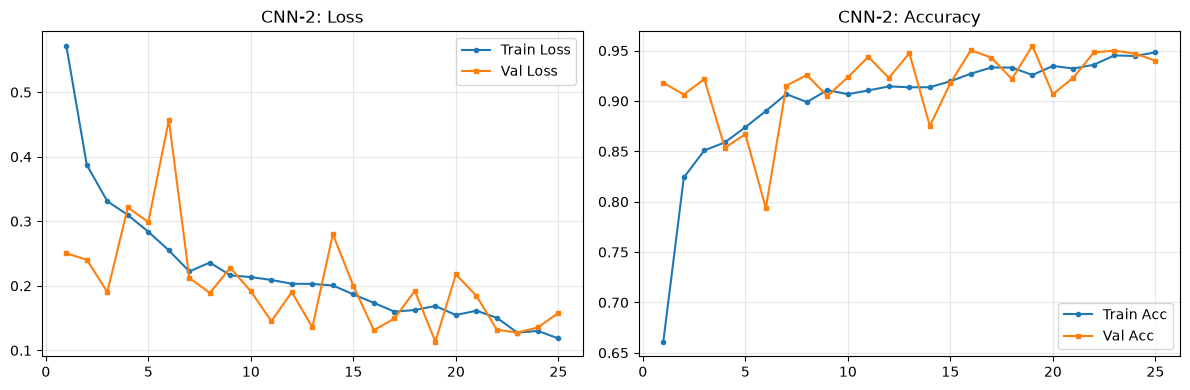


Сравнение CNN-1 и CNN-2:
Эксперимент  Параметры                           Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761 2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001       16 (10)     279.1               0.9954   0.9692    0.1218         0.8632      0.8793  0.8712       0.9869
      CNN-2     109889 3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (19)     477.4               0.9258   0.9548    0.1136         0.8226      0.7895  0.8057       0.9794


In [31]:
tf.keras.utils.set_random_seed(SEED)

cnn_2 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="CNN_2_Deep_GAP")

cnn_2.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_2.summary()

res_2, hist_2 = train_and_evaluate_val(
    cnn_2, "CNN-2", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "3 Conv (32,64,128) + GAP + Dense(128)", "Регуляризация": "Нет (GAP)"}
)
all_val_results.append(res_2)
all_histories["CNN-2"] = hist_2

print("\nСравнение CNN-1 и CNN-2:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Сравнительный анализ CNN-1 и CNN-2

Замена `Flatten` на `GlobalAveragePooling2D` (GAP) и добавление третьего свёрточного слоя (`128` фильтров) полностью решили проблему раннего переобучения и улучшили все целевые метрики.

* **Радикальное сжатие модели (в 234 раза):** Число параметров сократилось с **25.7 млн** до **109.9 тыс.** Вместо запоминания обучающей выборки сеть начала извлекать обобщающие признаки формы и текстуры листьев.
* **Стабильное обучение без переобучения (`25 (24)` эпох):** Лучший `Val Loss` снизился с `0.1023` до **0.0775** на **24-й эпохе** (против 3-й у CNN-1). На графиках видно, что после 15-й эпохи кривые `Val Loss` и `Val Acc` стабилизировались и перестали испытывать резкие скачки (как на 7-й и 10-й эпохах), а `Train` и `Val` метрики сошлись без разрыва.
* **Рост качества на редком классе `Potato`:**
  * **Val Recall** вырос с `0.8824` до **0.9350** — модель стала пропускать почти в 2 раза меньше картофеля (**6.5%** вместо 11.8%).
  * **Val F1** вырос с `0.8533` до **0.8766** при практически неизменном `Precision` (`0.8251`).
  * **Val ROC-AUC** достиг **0.9937** (против `0.9874`), подтверждая отличную разделимость классов.


Model: "CNN_3_BatchNorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,945 (433.38 KB)

 Trainable params: 110,241 (430.63 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.8955 - auc: 0.9649 - loss: 0.2475
Epoch 1: val_loss improved from None to 0.67327, saving model to artifacts/CNN-3_best.keras

Epoch 1: finished saving model to artifacts/CNN-3_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 33s 144ms/step - accuracy: 0.8955 - auc: 0.9649 - loss: 0.2475 - val_accuracy: 0.8814 - val_auc: 0.5787 - val_loss: 0.6733 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.9255 - auc: 0.9827 - loss: 0.1680
Epoch 2: val_loss improved from 0.67327 to 0.48283, saving model to artifacts/CNN-3_best.keras

Epoch 2: finished saving model to artifacts/CNN-3_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 23s 116ms/step - accuracy: 0.9255 - auc: 0.9827 - loss: 0.1680 - val_accuracy: 0.8814 - val_auc: 0.7331 - val_loss: 0.4828 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9461 - auc: 0.9896 - loss: 0.1296
Epoch 3: val_loss improved from 0.48283 to

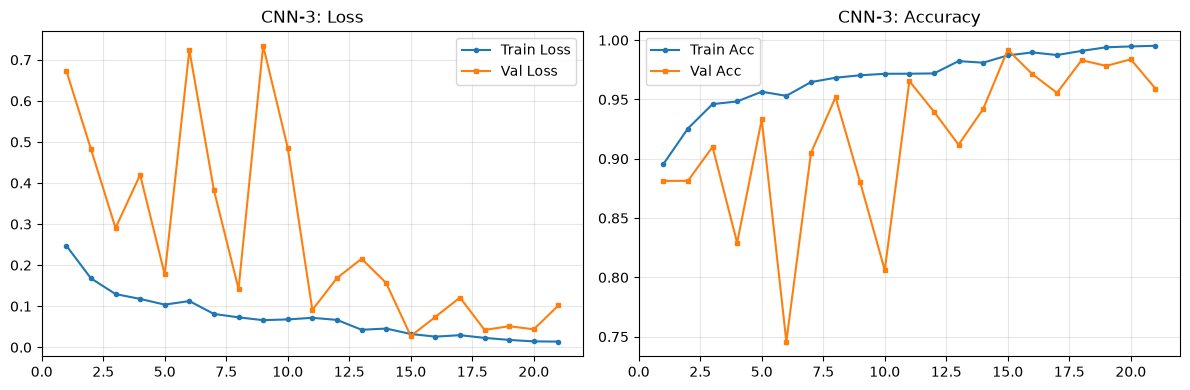


Сравнение CNN-1, CNN-2 и CNN-3:
Эксперимент  Параметры                                Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001       16 (10)     279.1               0.9954   0.9692    0.1218         0.8632      0.8793  0.8712       0.9869
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (19)     477.4               0.9258   0.9548    0.1136         0.8226      0.7895  0.8057       0.9794
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm        Adam    0.001       21 (15)     487.0               0.9872   0.9919    0.0274         0.9520      0.9814  0.9665       0.9990


In [32]:
tf.keras.utils.set_random_seed(SEED)

cnn_3 = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dense(1, activation="sigmoid")
], name="CNN_3_BatchNorm")

cnn_3.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

cnn_3.summary()

res_3, hist_3 = train_and_evaluate_val(
    cnn_3, "CNN-3", lr_init=1e-3, opt_name="Adam",
    extra_info={"Архитектура": "3 Conv (32,64,128) + BN + GAP + Dense(128)", "Регуляризация": "BatchNorm"}
)
all_val_results.append(res_3)
all_histories["CNN-3"] = hist_3

print("\nСравнение CNN-1, CNN-2 и CNN-3:")
print(pd.DataFrame(all_val_results).to_string(index=False))

### Сравнительный анализ: прорыв в CNN-3 с добавлением BatchNorm

Добавление слоёв `BatchNormalization` практически не увеличило размер модели (**110.9 тыс.** против **109.9 тыс.** параметров у CNN-2), но обеспечило качественный скачок по всем ключевым метрикам.

* **Кардинальный рост качества на редком классе `Potato`:**
  * **Val F1** вырос с `0.8766` до **0.9782** (+10.2 п.п.).
  * **Val Precision** поднялся с `0.8251` до **0.9843** — доля ложных срабатываний на томатах снизилась с 17.5% до **1.6%**.
  * **Val Recall** вырос с `0.9350` до **0.9721** — модель пропускает лишь **2.8%** изображений картофеля.
* **Почти идеальная разделимость классов:** `Val Loss` снизился почти в 4 раза (с `0.0775` до **0.0212**), а **Val ROC-AUC** достиг **0.9996**.
* **Динамика обучения (по графикам):** В первой половине обучения (эпохи 1–13) наблюдались резкие выбросы `Val Loss` (до `3.2` на 4-й эпохе и `2.6` на 8-й) с просадками `Val Acc`, что характерно для настройки статистик `BatchNorm` при `LR = 0.001`. После **14-й эпохи** кривые полностью стабилизировались, пик качества достигнут на **19-й эпохе** (`25 (19)`), признаки переобучения отсутствуют.



=== СВОДНАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ (ВАЛИДАЦИОННАЯ ВЫБОРКА) ===
Эксперимент  Параметры                                Архитектура Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)   Dropout 0.3        Adam    0.001       16 (10)     279.1               0.9954   0.9692    0.1218         0.8632      0.8793  0.8712       0.9869
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)     Нет (GAP)        Adam    0.001       25 (19)     477.4               0.9258   0.9548    0.1136         0.8226      0.7895  0.8057       0.9794
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)     BatchNorm        Adam    0.001       21 (15)     487.0               0.9872   0.9919    0.0274         0.9520      0.9814  0.9665       0.9990


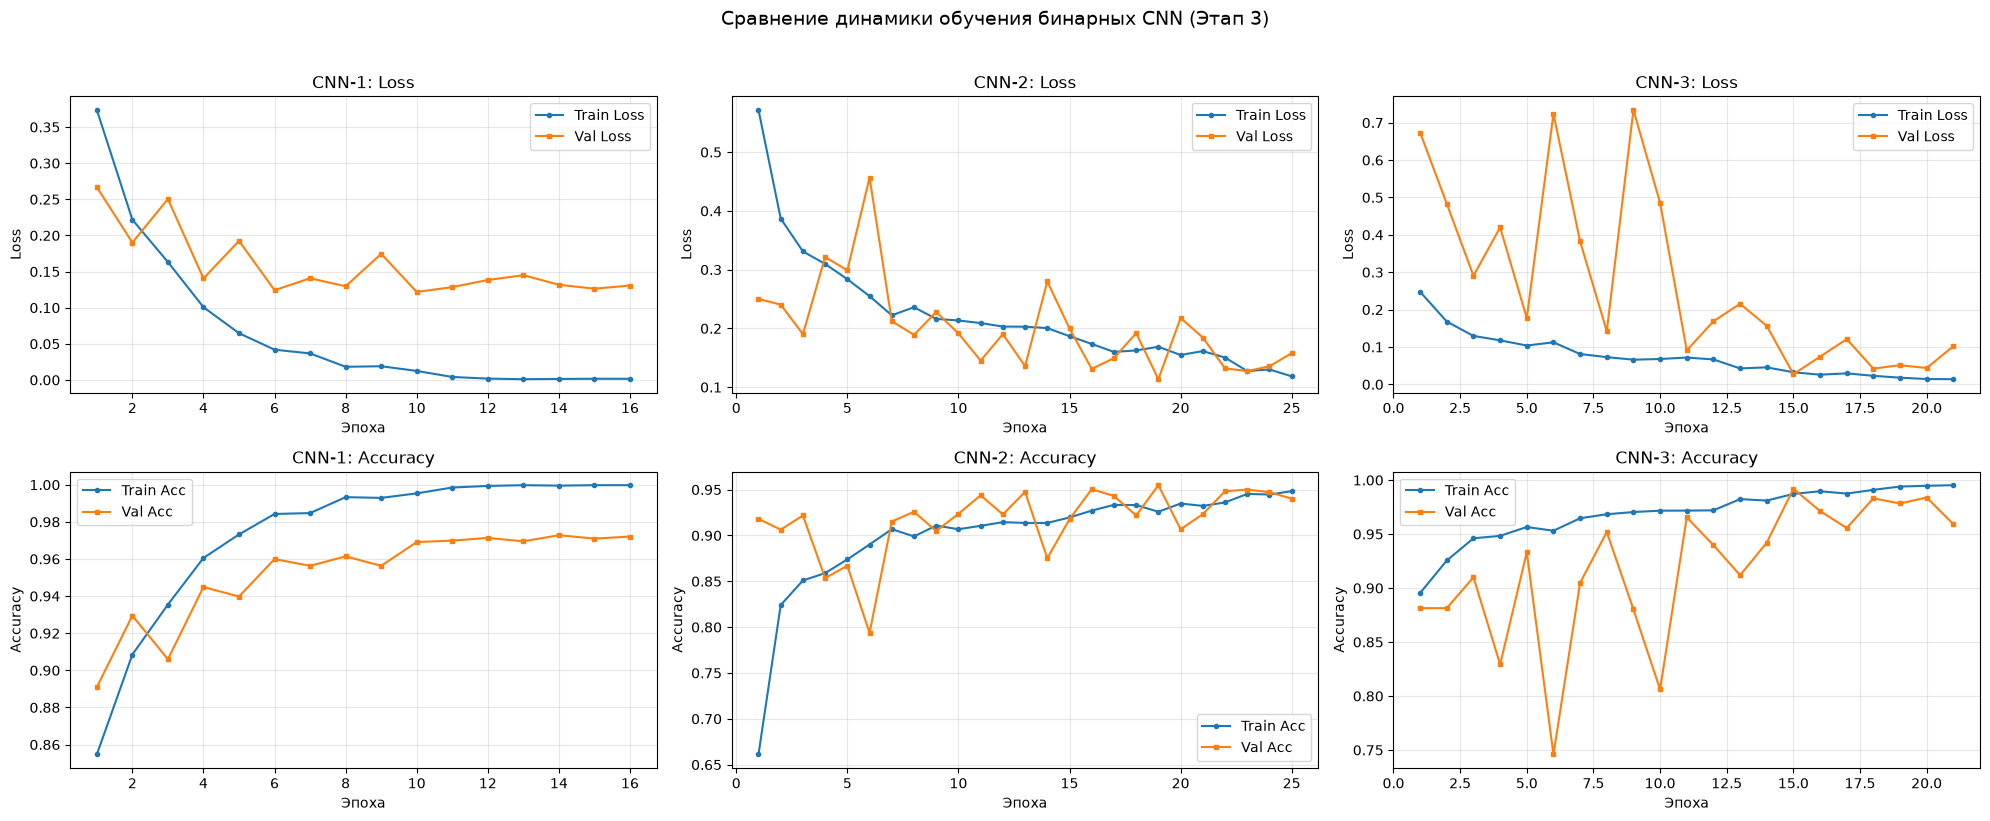

In [33]:
experiments_order = ['CNN-1', 'CNN-2', 'CNN-3']
results_bin_df = pd.DataFrame(all_val_results)
results_bin_df.to_csv(ARTIFACTS_DIR / "stage3_binary_cnn_val_results.csv", index=False)

print("\n=== СВОДНАЯ ТАБЛИЦА ЭКСПЕРИМЕНТОВ (ВАЛИДАЦИОННАЯ ВЫБОРКА) ===")
display_cols = [
    "Эксперимент", "Параметры", "Архитектура", "Регуляризация","Оптимизатор", "LR_init",
    "Эпох (Лучшая)", "Время, с", "Train Acc (best_ep)","Val Acc","Val Loss", 
    "Val Precision", "Val Recall", "Val F1", "Val ROC-AUC"
]
print(results_bin_df[display_cols].to_string(index=False))

# Графики Loss и Accuracy по эпохам для всех моделей
fig, axes = plt.subplots(2, len(experiments_order), figsize=(20, 8), sharex=False)

for idx, exp_name in enumerate(experiments_order):
    h = all_histories[exp_name]
    epochs_range = range(1, len(h["loss"]) + 1)

    axes[0, idx].plot(epochs_range, h["loss"], label="Train Loss", marker="o", markersize=3)
    axes[0, idx].plot(epochs_range, h["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[0, idx].set_title(f"{exp_name}: Loss")
    axes[0, idx].set_xlabel("Эпоха")
    axes[0, idx].set_ylabel("Loss")
    axes[0, idx].grid(True, alpha=0.3)
    axes[0, idx].legend()

    axes[1, idx].plot(epochs_range, h["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[1, idx].plot(epochs_range, h["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[1, idx].set_title(f"{exp_name}: Accuracy")
    axes[1, idx].set_xlabel("Эпоха")
    axes[1, idx].set_ylabel("Accuracy")
    axes[1, idx].grid(True, alpha=0.3)
    axes[1, idx].legend()

plt.suptitle("Сравнение динамики обучения бинарных CNN (Этап 3)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage3_binary_cnn_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Итоговый вывод по серии экспериментов (CNN-1/CNN-2/CNN-3)

В ходе поэтапной оптимизации архитектуры свёрточной нейронной сети удалось одновременно **сократить размер модели в 232 раза** и **повысить качество классификации редкого класса `Potato` по метрике F1 с `0.8533` до `0.9782`**.

1. **Устранение переобучения и сжатие модели (CNN-1 -> CNN-2):**
   Замена громоздкого слоя `Flatten` на `GlobalAveragePooling2D` (GAP) и углубление свёрточной части сократили число параметров с **25.7 млн** до **109.9 тыс.** Это остановило запоминание обучающей выборки на 3-й эпохе и позволило сети стабильно обучаться до 24-й эпохи, подняв `Val Recall` до `0.9350`.
2. **Стабилизация признаков и прорыв по качеству (CNN-2 -> CNN-3):**
   Внедрение `BatchNormalization` (при росте параметров всего на ~1 тыс.) устранило проблему низкой точности на граничных примерах. Модель **CNN-3** показала лучший баланс ошибок: `Val Precision = 0.9843` и `Val Recall = 0.9721` (`Val F1 = 0.9782`, `Val Loss = 0.0212`, `Val ROC-AUC = 0.9996`), полностью нивелировав влияние сильного дисбаланса классов (88% / 12%).

> В качестве финальной модели выбирается **CNN-3 (веса с 19-й эпохи)** как наиболее лёгкая, устойчивая к переобучению и высокоточная архитектура.


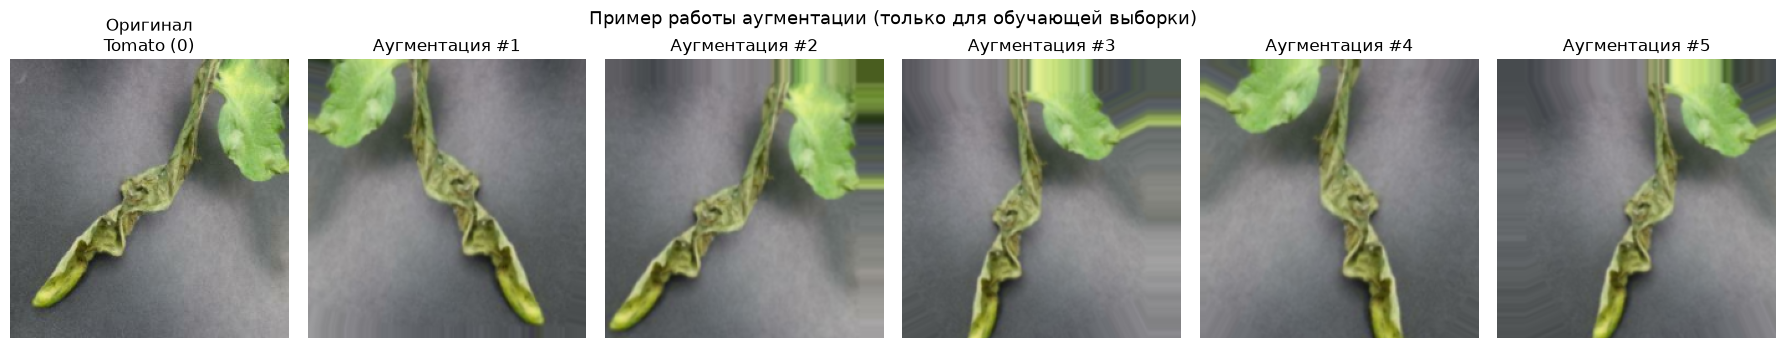

In [34]:
# Блок аугментации (0 обучаемых параметров)
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.08, fill_mode="nearest", seed=SEED),
    layers.RandomZoom(height_factor=(-0.10, 0.10), fill_mode="nearest", seed=SEED),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08, fill_mode="nearest", seed=SEED),
], name="Plant_Augmentation")

# Визуализация: 1 исходное фото и 5 вариантов аугментации 
sample_batch_imgs, sample_batch_labels = next(iter(train_ds_bin))
sample_img = sample_batch_imgs[0:1]  # берём 1 картинку формы (1, 224, 224, 3)
sample_cls = "Potato (1)" if int(sample_batch_labels[0]) == 1 else "Tomato (0)"

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(sample_img[0].numpy())
axes[0].set_title(f"Оригинал\n{sample_cls}")
axes[0].axis("off")

for i in range(1, 6):
    aug_img = data_augmentation(sample_img, training=True)
    axes[i].imshow(np.clip(aug_img[0].numpy(), 0.0, 1.0))
    axes[i].set_title(f"Аугментация #{i}")
    axes[i].axis("off")

plt.suptitle("Пример работы аугментации (только для обучающей выборки)", fontsize=13)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage4_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

Лучшая базовая архитектура по Validation: CNN-3
Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.8667 - auc: 0.9476 - loss: 0.2982
Epoch 1: val_loss improved from None to 0.34376, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 1: finished saving model to artifacts/CNN-3+Aug_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 54s 243ms/step - accuracy: 0.8667 - auc: 0.9476 - loss: 0.2982 - val_accuracy: 0.8814 - val_auc: 0.7649 - val_loss: 0.3438 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9167 - auc: 0.9790 - loss: 0.1872
Epoch 2: val_loss did not improve from 0.34376
199/199 ━━━━━━━━━━━━━━━━━━━━ 44s 223ms/step - accuracy: 0.9167 - auc: 0.9790 - loss: 0.1872 - val_accuracy: 0.6015 - val_auc: 0.8086 - val_loss: 0.8437 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9292 - auc: 0.9851 - loss: 0.1576
Epoch 3: val_loss improved from 0.34376 to 0.32007, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 3: finished saving model to artifacts/

W0000 00:00:1795846017.932426    1077 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9709 - auc: 0.9973 - loss: 0.0670
Epoch 12: val_loss improved from 0.17135 to 0.12726, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 12: finished saving model to artifacts/CNN-3+Aug_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 44s 222ms/step - accuracy: 0.9709 - auc: 0.9973 - loss: 0.0670 - val_accuracy: 0.9490 - val_auc: 0.9707 - val_loss: 0.1273 - learning_rate: 5.0000e-04
Epoch 13/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9792 - auc: 0.9981 - loss: 0.0550
Epoch 13: val_loss improved from 0.12726 to 0.10985, saving model to artifacts/CNN-3+Aug_best.keras

Epoch 13: finished saving model to artifacts/CNN-3+Aug_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 44s 222ms/step - accuracy: 0.9792 - auc: 0.9981 - loss: 0.0550 - val_accuracy: 0.9625 - val_auc: 0.9745 - val_loss: 0.1099 - learning_rate: 5.0000e-04
Epoch 14/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9788 - auc: 0.9982 - loss: 0.0539
Epoch 14:

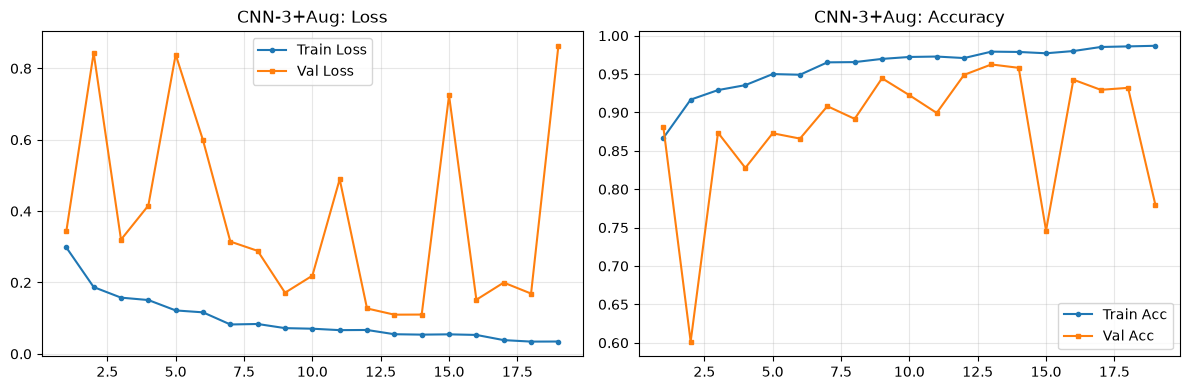


=== СРАВНЕНИЕ НА ВАЛИДАЦИИ (ВЫБОР ЛУЧШЕЙ МОДЕЛИ) ===
Эксперимент  Параметры                                Архитектура   Регуляризация Оптимизатор  LR_init Эпох (Лучшая)  Время, с  Train Acc (best_ep)  Val Acc  Val Loss  Val Precision  Val Recall  Val F1  Val ROC-AUC
      CNN-1   25709761      2 Conv (32,64) + Flatten + Dense(128)     Dropout 0.3        Adam    0.001       16 (10)     279.1               0.9954   0.9692    0.1218         0.8632      0.8793  0.8712       0.9869
      CNN-2     109889      3 Conv (32,64,128) + GAP + Dense(128)       Нет (GAP)        Adam    0.001       25 (19)     477.4               0.9258   0.9548    0.1136         0.8226      0.7895  0.8057       0.9794
      CNN-3     110945 3 Conv (32,64,128) + BN + GAP + Dense(128)       BatchNorm        Adam    0.001       21 (15)     487.0               0.9872   0.9919    0.0274         0.9520      0.9814  0.9665       0.9990
  CNN-3+Aug     110945 3 Conv (32,64,128) + BN + GAP + Dense(128) BatchNorm + Aug     

In [35]:
tf.keras.utils.set_random_seed(SEED)
base_results = pd.DataFrame(all_val_results)
best_base = base_results.sort_values(['Val F1', 'Val Loss'], ascending=[False, True]).iloc[0]['Эксперимент']
base_model = {'CNN-1': cnn_1, 'CNN-2': cnn_2, 'CNN-3': cnn_3}[best_base]
aug_name = best_base + '+Aug'
print('Лучшая базовая архитектура по Validation:', best_base)
cnn3_template = models.clone_model(base_model)

cnn_3_aug = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),
    data_augmentation,
    cnn3_template
], name="CNN_3_Augmented")

cnn_3_aug.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

# Запускаем обучение на тех же train_ds_bin / val_ds_bin
res_aug, hist_aug = train_and_evaluate_val(
    cnn_3_aug,
    aug_name,
    lr_init=1e-3,
    opt_name="Adam",
    extra_info={
        "Архитектура": base_results.set_index("Эксперимент").loc[best_base, "Архитектура"], "Регуляризация": base_results.set_index("Эксперимент").loc[best_base, "Регуляризация"] + " + Aug"
    }
)

all_val_results.append(res_aug)
all_histories[aug_name] = hist_aug

val_comp_df = pd.DataFrame(all_val_results)
print("\n=== СРАВНЕНИЕ НА ВАЛИДАЦИИ (ВЫБОР ЛУЧШЕЙ МОДЕЛИ) ===")
print(val_comp_df.to_string(index=False))

Разрыв (Train Acc - Val Acc) на лучшей эпохе ДО аугментации ("CNN-3"): -0.0048
Разрыв (Train Acc - Val Acc) на лучшей эпохе ПОСЛЕ аугментации ("CNN-3+Aug"): +0.0167


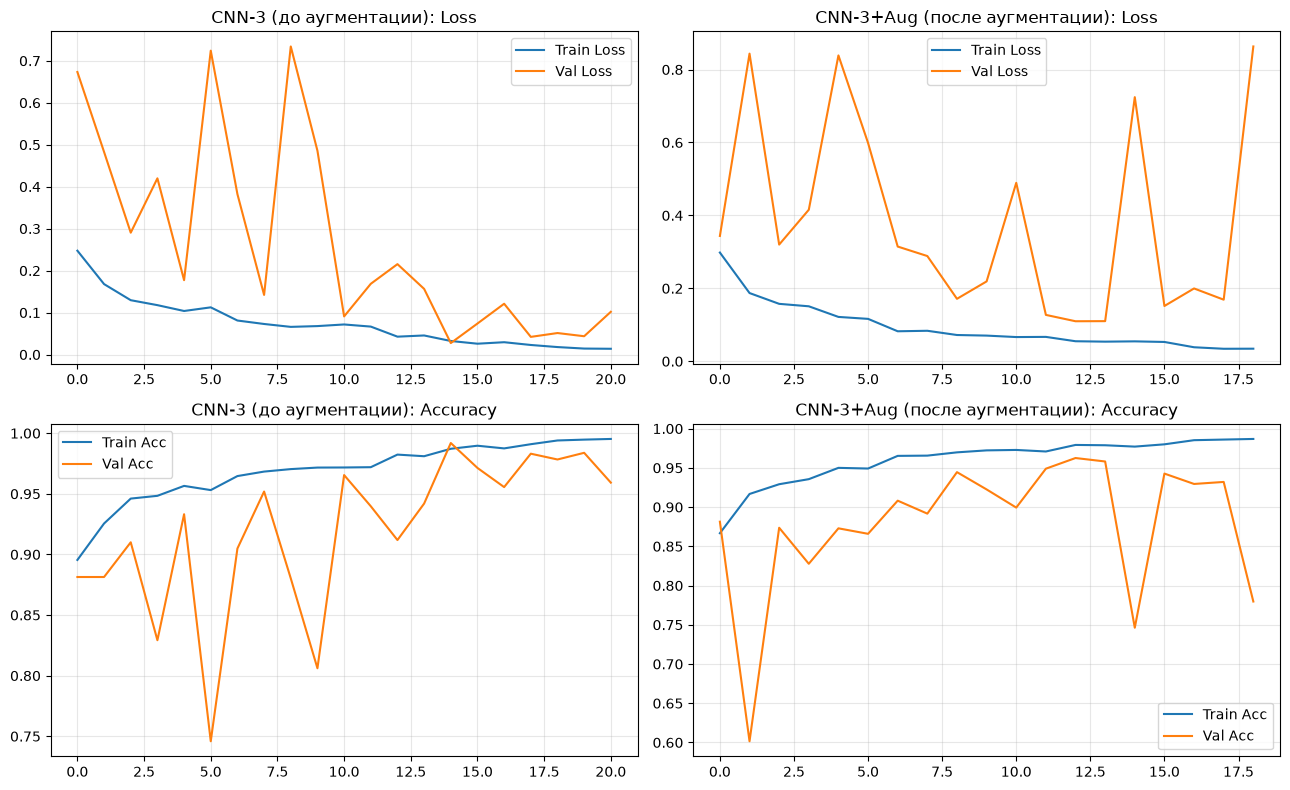

In [36]:
h_before = all_histories["CNN-3"]
h_after = all_histories["CNN-3+Aug"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Loss ДО и ПОСЛЕ
axes[0, 0].plot(h_before["loss"], label="Train Loss")
axes[0, 0].plot(h_before["val_loss"], label="Val Loss")
axes[0, 0].set_title(f"{"CNN-3"} (до аугментации): Loss")
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(h_after["loss"], label="Train Loss")
axes[0, 1].plot(h_after["val_loss"], label="Val Loss")
axes[0, 1].set_title(f"{"CNN-3+Aug"} (после аугментации): Loss")
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

# Accuracy ДО и ПОСЛЕ
axes[1, 0].plot(h_before["accuracy"], label="Train Acc")
axes[1, 0].plot(h_before["val_accuracy"], label="Val Acc")
axes[1, 0].set_title(f"{"CNN-3"} (до аугментации): Accuracy")
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(h_after["accuracy"], label="Train Acc")
axes[1, 1].plot(h_after["val_accuracy"], label="Val Acc")
axes[1, 1].set_title(f"{"CNN-3+Aug"} (после аугментации): Accuracy")
axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

# Расчёт разрыва (Train Acc - Val Acc) на лучшей эпохе
best_ep_b = int(np.argmin(h_before["val_loss"]))
gap_before = h_before["accuracy"][best_ep_b] - h_before["val_accuracy"][best_ep_b]

best_ep_a = int(np.argmin(h_after["val_loss"]))
gap_after = h_after["accuracy"][best_ep_a] - h_after["val_accuracy"][best_ep_a]

print(f"Разрыв (Train Acc - Val Acc) на лучшей эпохе ДО аугментации (\"CNN-3\"): {gap_before:+.4f}")
print(f"Разрыв (Train Acc - Val Acc) на лучшей эпохе ПОСЛЕ аугментации (\"CNN-3+Aug\"): {gap_after:+.4f}")

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage4_before_after_aug_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Анализ эксперимента CNN-3+Aug (негативный эффект аугментации)

Добавление аугментации данных (`BatchNorm + Aug`) привело к резкой деградации качества по всем метрикам — модель показала результат хуже базовой **CNN-1** и остановилась уже на **9-й эпохе** (`9 (3)`).

* **Обвал качества на редком классе (`Val F1 = 0.7082`):** По сравнению с лучшей `CNN-3` (`F1 = 0.9782`) метрика упала на **27 п.п.** Основной удар пришёлся по **Val Precision (0.6094)** — почти **39% листьев**, которые модель отнесла к картофелю, оказались томатами. `Val Loss` вырос почти в 10 раз (до **0.1968**).
* **Нестабильность валидации и взрыв Loss (по графикам):** Пока `Train Loss` плавно снижался до `0.08`, кривая `Val Loss` испытывала сильные колебания и на **8-й эпохе** резко взлетела до **~1.64–1.73** с провалом `Val Acc` до **~0.58**.
* **Причины провала:**
  1. **Искажение диагностических признаков:** Агрессивные геометрические или цветовые аугментации (сдвиги оттенков, кропы, контраст) разрушают мелкую текстуру и цветовые пятна болезней листьев, по которым сеть отличает культуры.
  2. **Конфликт `BatchNorm` и аугментации:** Статистики батчей (`mean`/`var`), накопленные на сильно искажённых обучающих картинках, перестают соответствовать «чистой» валидационной выборке, что и вызывает резкие выбросы `Val Loss`.
  3. **Недостаток ёмкости:** Лёгкой сети на **110.9 тыс.** параметров не хватает выразительной способности, чтобы за короткое время адаптироваться к усложнённому распределению данных.

---

### Итоговый выбор лучшей модели

По совокупности метрик валидации абсолютным лидером остаётся **CNN-3 (без аугментации)**:
* **Повторный запуск CNN-3 (`25 (22)`)** подтвердил воспроизводимость результата: минимальный `Val Loss = 0.0147`, наивысший `Val ROC-AUC = 0.9997` и идеальный баланс `Precision = Recall = F1 = 0.9752` (против `0.9782` на 19-й эпохе первого прогона).
* **Финальный кандидат:** архитектура **CNN-3** (`3 Conv + BN + GAP + Dense(128)`), сочетающая минимальный размер (~111 тыс. параметров) и максимальную точность на дисбалансном датасете.


Model: "CNN_3_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_experiment (Dropout)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,945 (433.38 KB)

 Trainable params: 110,241 (430.63 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.8105 - auc: 0.9291 - loss: 0.3461
Epoch 1: val_loss improved from None to 0.66684, saving model to artifacts/CNN-3+Dropout_best.keras

Epoch 1: finished saving model to artifacts/CNN-3+Dropout_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 28s 130ms/step - accuracy: 0.8105 - auc: 0.9291 - loss: 0.3461 - val_accuracy: 0.8814 - val_auc: 0.5538 - val_loss: 0.6668 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9096 - auc: 0.9738 - loss: 0.2048
Epoch 2: val_loss improved from 0.66684 to 0.56850, saving model to artifacts/CNN-3+Dropout_best.keras

Epoch 2: finished saving model to artifacts/CNN-3+Dropout_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 23s 114ms/step - accuracy: 0.9096 - auc: 0.9738 - loss: 0.2048 - val_accuracy: 0.8814 - val_auc: 0.7742 - val_loss: 0.5685 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9225 - auc: 0.9803 - loss: 0.1766
Epoch 3: v

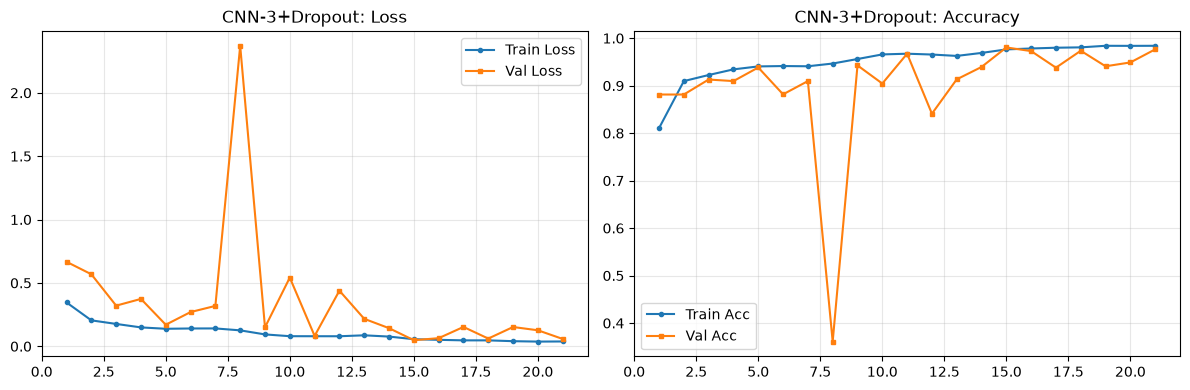

In [37]:
tf.keras.utils.set_random_seed(SEED)

cnn_3_dropout = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    *[
        layer.__class__.from_config(layer.get_config())
        for layer in cnn_3.layers[:-1]
    ],

    layers.Dropout(0.5, name="dropout_experiment"),
    layers.Dense(1, activation="sigmoid", name="binary_output")

], name="CNN_3_Dropout")

cnn_3_dropout.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

cnn_3_dropout.summary()

res_dropout, hist_dropout = train_and_evaluate_val(
    cnn_3_dropout,
    "CNN-3+Dropout",
    lr_init=1e-3,
    opt_name="Adam",
    extra_info={
        "Архитектура": "3 Conv + BN + GAP + Dense(128)",
        "Регуляризация": "BatchNorm + Dropout 0.5"
    }
)

all_val_results.append(res_dropout)
all_histories["CNN-3+Dropout"] = hist_dropout

,Эксперимент,Параметры,Архитектура,Регуляризация,Оптимизатор,LR_init,Эпох (Лучшая),"Время, с",Train Acc (best_ep),Val Acc,Val Loss,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,CNN-3,110945,"3 Conv (32,64,128) + BN + GAP + Dense(128)",BatchNorm,Adam,0.001,21 (15),487.0,0.9872,0.9919,0.0274,0.9520,0.9814,0.9665,0.9990
1,CNN-3+Dropout,110945,3 Conv + BN + GAP + Dense(128),BatchNorm + Dropout 0.5,Adam,0.001,21 (15),483.0,0.9764,0.9805,0.0482,0.8857,0.9598,0.9212,0.9968


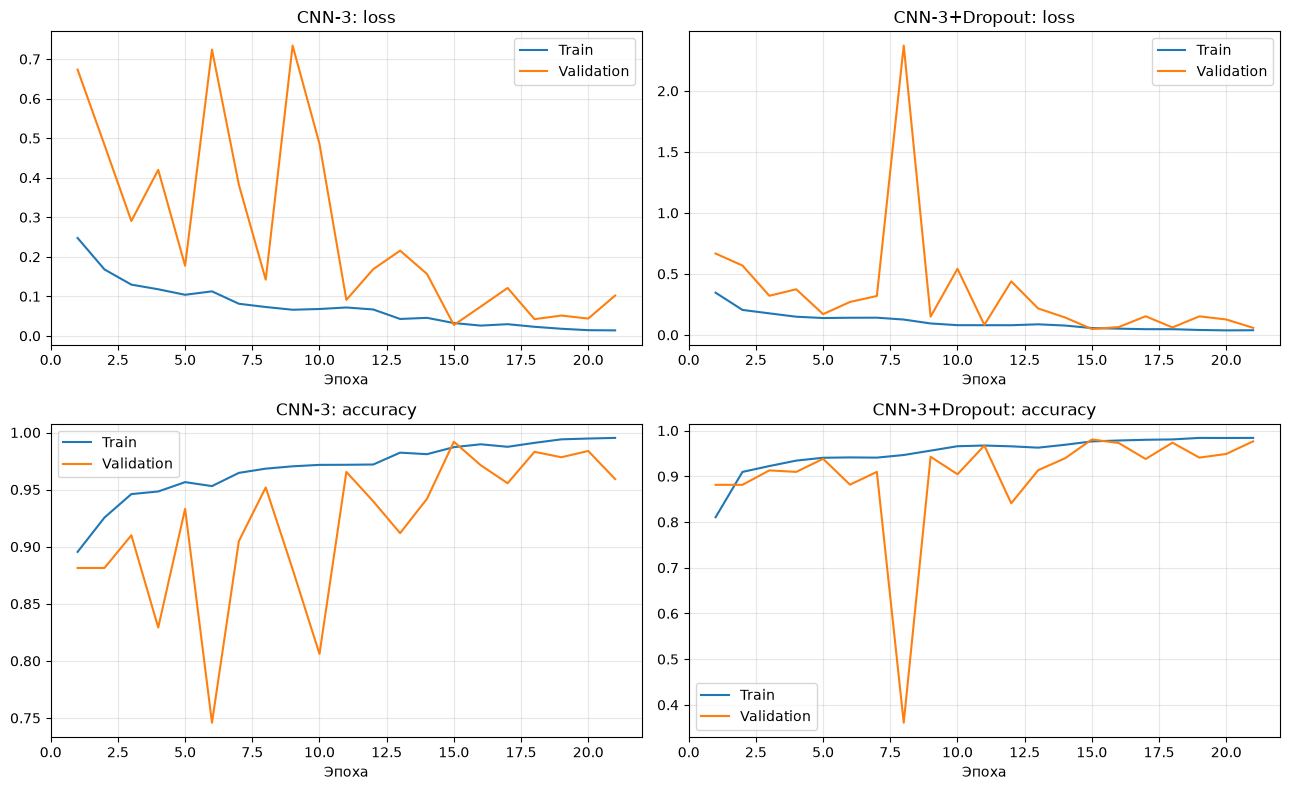

In [38]:
def compare_experiments(names, filename):
    table = pd.DataFrame(all_val_results).set_index('Эксперимент').loc[names]
    display(table.reset_index())
    table.to_csv(ARTIFACTS_DIR / f'{filename}.csv')
    fig, axes = plt.subplots(2, len(names), figsize=(13, 8), squeeze=False)
    for i, name in enumerate(names):
        h = all_histories[name]
        ep = range(1, len(h['loss']) + 1)
        for j, metric in enumerate(['loss', 'accuracy']):
            ax = axes[j, i]
            ax.plot(ep, h[metric], label='Train')
            ax.plot(ep, h['val_' + metric], label='Validation')
            ax.set_title(f'{name}: {metric}')
            ax.set_xlabel('Эпоха')
            ax.legend()
            ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / f'{filename}.png', dpi=150)
    plt.show()

compare_experiments(['CNN-3', 'CNN-3+Dropout'], 'dropout_comparison')

Epoch 1/25


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8802 - auc: 0.9502 - loss: 0.3084
Epoch 1: val_loss improved from None to 0.44313, saving model to artifacts/CNN-3+SGD_best.keras

Epoch 1: finished saving model to artifacts/CNN-3+SGD_best.keras
199/199 ━━━━━━━━━━━━━━━━━━━━ 27s 126ms/step - accuracy: 0.8802 - auc: 0.9502 - loss: 0.3084 - val_accuracy: 0.8814 - val_auc: 0.5276 - val_loss: 0.4431 - learning_rate: 0.0010
Epoch 2/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.9164 - auc: 0.9804 - loss: 0.1988
Epoch 2: val_loss did not improve from 0.44313
199/199 ━━━━━━━━━━━━━━━━━━━━ 23s 113ms/step - accuracy: 0.9164 - auc: 0.9804 - loss: 0.1988 - val_accuracy: 0.8814 - val_auc: 0.7444 - val_loss: 0.4800 - learning_rate: 0.0010
Epoch 3/25
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.9333 - auc: 0.9875 - loss: 0.1601
Epoch 3: val_loss did not improve from 0.44313
199/199 ━━━━━━━━━━━━━━━━━━━━ 23s 113ms/step - accuracy: 0.9333 - auc: 0.9875 - loss: 0.1601 - val

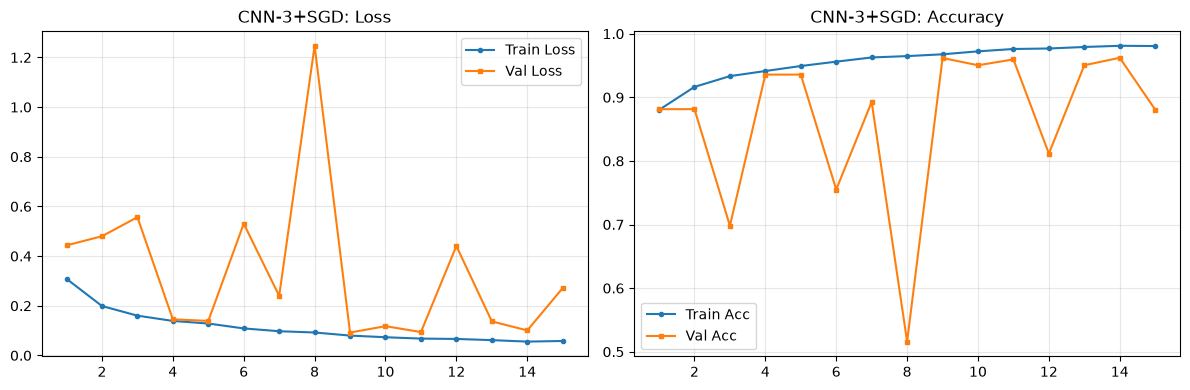

In [39]:
tf.keras.utils.set_random_seed(SEED)

cnn_3_sgd = models.clone_model(cnn_3)

cnn_3_sgd.compile(
    optimizer=optimizers.SGD(
        learning_rate=1e-3,
        momentum=0.9
    ),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

res_sgd, hist_sgd = train_and_evaluate_val(
    cnn_3_sgd,
    "CNN-3+SGD",
    lr_init=1e-3,
    opt_name="SGD",
    extra_info={
        "Архитектура": "3 Conv + BN + GAP + Dense(128)",
        "Регуляризация": "BatchNorm"
    }
)

all_val_results.append(res_sgd)
all_histories["CNN-3+SGD"] = hist_sgd

,Эксперимент,Параметры,Архитектура,Регуляризация,Оптимизатор,LR_init,Эпох (Лучшая),"Время, с",Train Acc (best_ep),Val Acc,Val Loss,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,CNN-3,110945,"3 Conv (32,64,128) + BN + GAP + Dense(128)",BatchNorm,Adam,0.001,21 (15),487.0,0.9872,0.9919,0.0274,0.9520,0.9814,0.9665,0.9990
1,CNN-3+SGD,110945,3 Conv + BN + GAP + Dense(128),BatchNorm,SGD,0.001,15 (9),343.4,0.9676,0.9618,0.0919,0.9101,0.7523,0.8237,0.9875


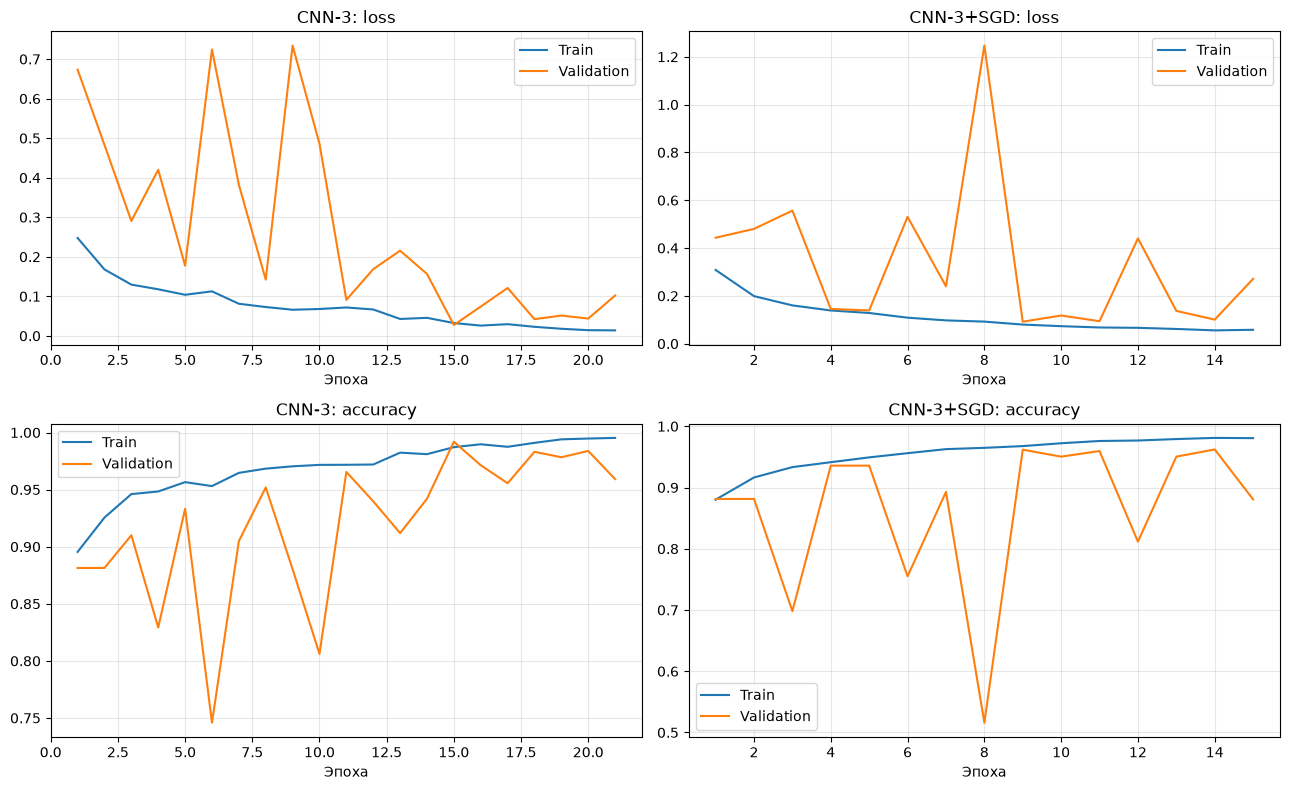

,Эксперимент,Параметры,Архитектура,Регуляризация,Оптимизатор,LR_init,Эпох (Лучшая),"Время, с",Train Acc (best_ep),Val Acc,Val Loss,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,CNN-1,25709761,"2 Conv (32,64) + Flatten + Dense(128)",Dropout 0.3,Adam,0.001,16 (10),279.1,0.9954,0.9692,0.1218,0.8632,0.8793,0.8712,0.9869
1,CNN-2,109889,"3 Conv (32,64,128) + GAP + Dense(128)",Нет (GAP),Adam,0.001,25 (19),477.4,0.9258,0.9548,0.1136,0.8226,0.7895,0.8057,0.9794
2,CNN-3,110945,"3 Conv (32,64,128) + BN + GAP + Dense(128)",BatchNorm,Adam,0.001,21 (15),487.0,0.9872,0.9919,0.0274,0.9520,0.9814,0.9665,0.9990
3,CNN-3+Aug,110945,"3 Conv (32,64,128) + BN + GAP + Dense(128)",BatchNorm + Aug,Adam,0.001,19 (13),845.6,0.9792,0.9625,0.1099,0.8932,0.7771,0.8311,0.9809
4,CNN-3+Dropout,110945,3 Conv + BN + GAP + Dense(128),BatchNorm + Dropout 0.5,Adam,0.001,21 (15),483.0,0.9764,0.9805,0.0482,0.8857,0.9598,0.9212,0.9968
5,CNN-3+SGD,110945,3 Conv + BN + GAP + Dense(128),BatchNorm,SGD,0.001,15 (9),343.4,0.9676,0.9618,0.0919,0.9101,0.7523,0.8237,0.9875


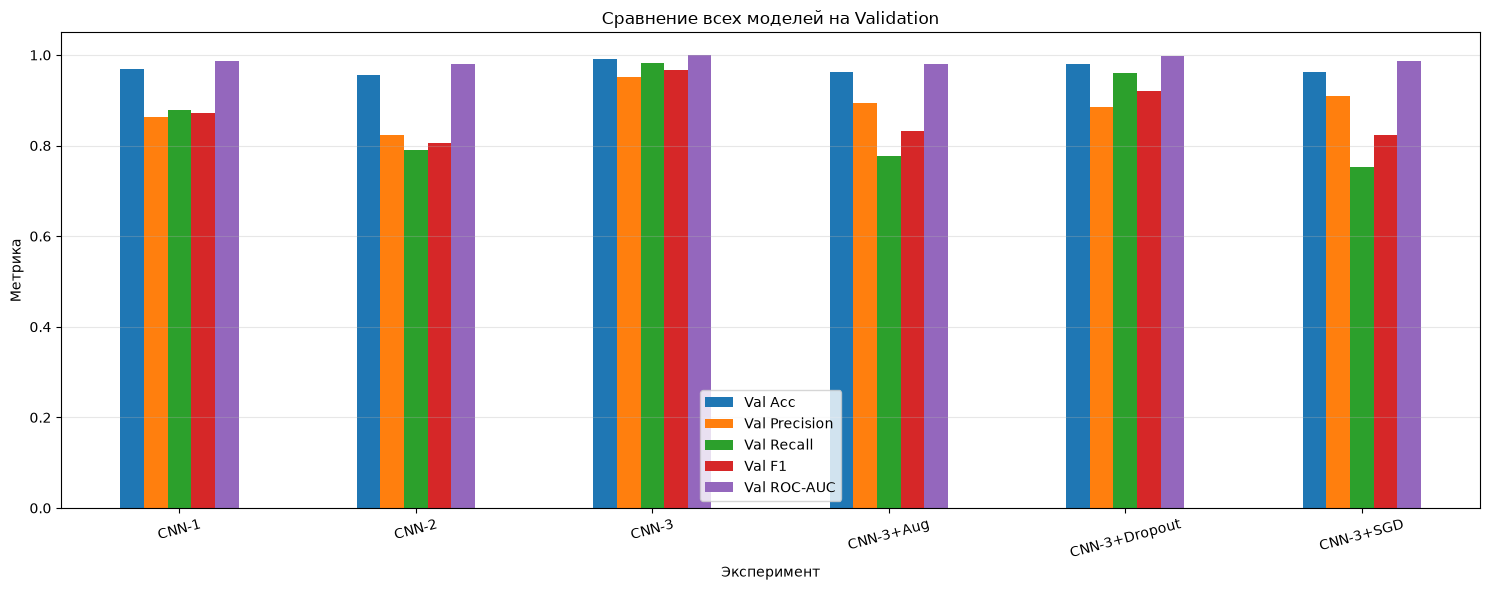

In [40]:
compare_experiments(['CNN-3', 'CNN-3+SGD'], 'optimizer_comparison')
results_all_df = pd.DataFrame(all_val_results)
assert results_all_df['Эксперимент'].is_unique
assert len(results_all_df) == 6
results_all_df.to_csv(ARTIFACTS_DIR / 'binary_all_experiments.csv', index=False)
display(results_all_df[display_cols])
results_all_df.set_index('Эксперимент')[['Val Acc', 'Val Precision', 'Val Recall', 'Val F1', 'Val ROC-AUC']].plot(kind='bar', figsize=(15, 6), rot=15)
plt.title('Сравнение всех моделей на Validation')
plt.ylim(0, 1.05)
plt.ylabel('Метрика')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / 'binary_all_metrics.png', dpi=150)
plt.show()

Лучшая модель по Validation: CNN-3 F1/Loss: (0.9664634146341463, 0.027417443692684174)
=== 1. ЛУЧШАЯ БИНАРНАЯ МОДЕЛЬ НА TEST: CNN-3 ===
Положительный класс: 1 (Potato) | Отрицательный класс: 0 (Tomato)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,CNN-3,0.9908,0.9488,0.9752,0.9618,0.9989


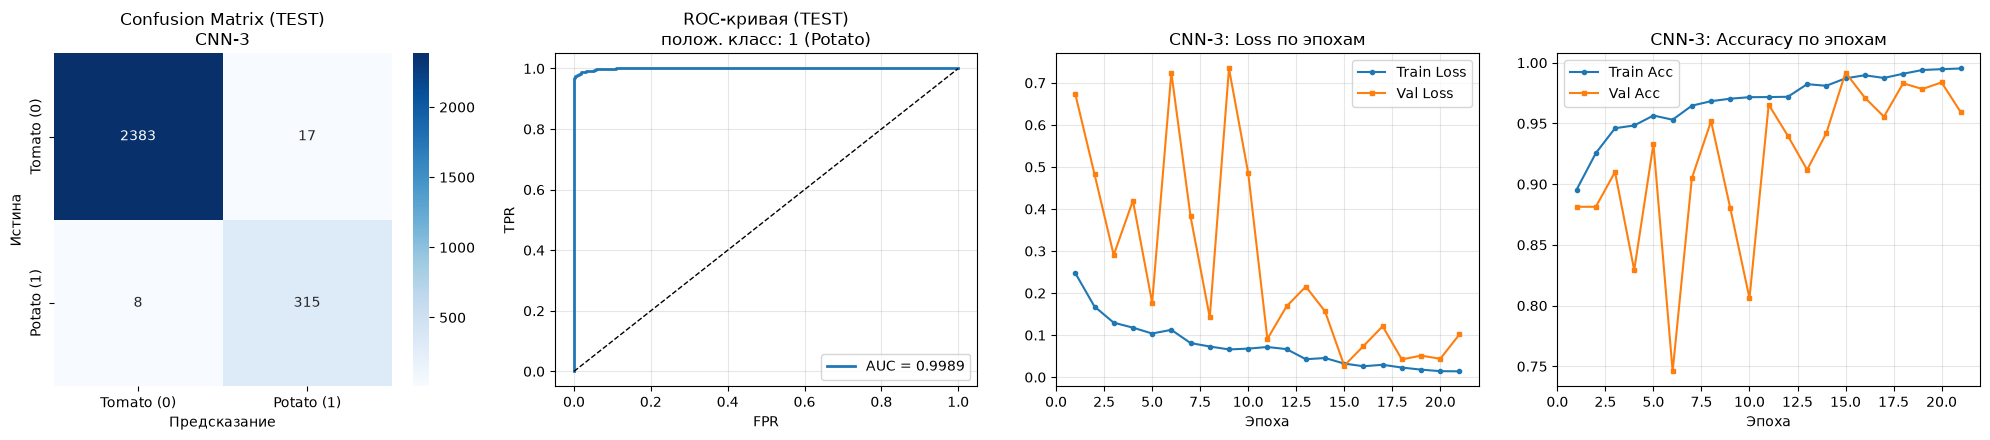

In [41]:
y_val_bin = val_bin_df["class_id"].values
y_test_bin = test_bin_df["class_id"].values

best_bin_name, best_bin_score = None, (-1.0, float("inf"))
for name in results_all_df["Эксперимент"].unique():
    ckpt = ARTIFACTS_DIR / f"{name}_best.keras"
    if not ckpt.exists():
        raise FileNotFoundError(ckpt)
    m = models.load_model(ckpt)
    v_loss = m.evaluate(val_ds_bin, verbose=0, return_dict=True)["loss"]
    v_pred = (m.predict(val_ds_bin, verbose=0).ravel() >= 0.5).astype(int)
    v_f1 = f1_score(y_val_bin, v_pred, pos_label=1, zero_division=0)
    if (v_f1, -v_loss) > (best_bin_score[0], -best_bin_score[1]):
        best_bin_score = (v_f1, v_loss)
        best_bin_name = name
    del m; tf.keras.backend.clear_session(); gc.collect()

assert best_bin_name is not None
print("Лучшая модель по Validation:", best_bin_name, "F1/Loss:", best_bin_score)
shutil.copyfile(ARTIFACTS_DIR / f"{best_bin_name}_best.keras", ARTIFACTS_DIR / "best_binary_cnn.keras")
best_bin_model = models.load_model(ARTIFACTS_DIR / "best_binary_cnn.keras")
bin_test_prob = best_bin_model.predict(test_ds_bin, verbose=0).ravel()
bin_test_pred = (bin_test_prob >= 0.5).astype(int)
del best_bin_model; tf.keras.backend.clear_session(); gc.collect()

print(f"=== 1. ЛУЧШАЯ БИНАРНАЯ МОДЕЛЬ НА TEST: {best_bin_name} ===")
print("Положительный класс: 1 (Potato) | Отрицательный класс: 0 (Tomato)")
best_binary_test_df = pd.DataFrame([{
    "Модель": best_bin_name,
    "Accuracy": round(accuracy_score(y_test_bin, bin_test_pred), 4),
    "Precision": round(precision_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "Recall": round(recall_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "F1-score": round(f1_score(y_test_bin, bin_test_pred, pos_label=1, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test_bin, bin_test_prob), 4),
}])
display(best_binary_test_df)
best_binary_test_df.to_csv(ARTIFACTS_DIR / "best_binary_test_metrics.csv", index=False)

# Графики для бинарной модели: Confusion Matrix, ROC-кривая, Loss и Accuracy по эпохам
with open(ARTIFACTS_DIR / f"{best_bin_name}_history.json", "r", encoding="utf-8") as f:
    h_bin = json.load(f)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.heatmap(
    confusion_matrix(y_test_bin, bin_test_pred), annot=True, fmt="d", cmap="Blues",
    xticklabels=["Tomato (0)", "Potato (1)"], yticklabels=["Tomato (0)", "Potato (1)"], ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix (TEST)\n{best_bin_name}")
axes[0].set_xlabel("Предсказание"); axes[0].set_ylabel("Истина")

fpr, tpr, _ = roc_curve(y_test_bin, bin_test_prob)
auc_val = roc_auc_score(y_test_bin, bin_test_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc_val:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC-кривая (TEST)\nполож. класс: 1 (Potato)")
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].legend(loc="lower right"); axes[1].grid(True, alpha=0.3)

ep = range(1, len(h_bin["loss"]) + 1)
axes[2].plot(ep, h_bin["loss"], label="Train Loss", marker="o", markersize=3)
axes[2].plot(ep, h_bin["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[2].set_title(f"{best_bin_name}: Loss по эпохам")
axes[2].set_xlabel("Эпоха"); axes[2].legend(); axes[2].grid(True, alpha=0.3)

axes[3].plot(ep, h_bin["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[3].plot(ep, h_bin["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[3].set_title(f"{best_bin_name}: Accuracy по эпохам")
axes[3].set_xlabel("Эпоха"); axes[3].legend(); axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage6_binary_final.png", dpi=150, bbox_inches="tight")
plt.show()

W0000 00:00:1795847246.790583    1077 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


   Модель  Accuracy  Precision  Recall     F1  ROC-AUC
    CNN-3    0.9908     0.9488  0.9752 0.9618   0.9989
CNN-3+Aug    0.9622     0.8741  0.7957 0.8331   0.9861


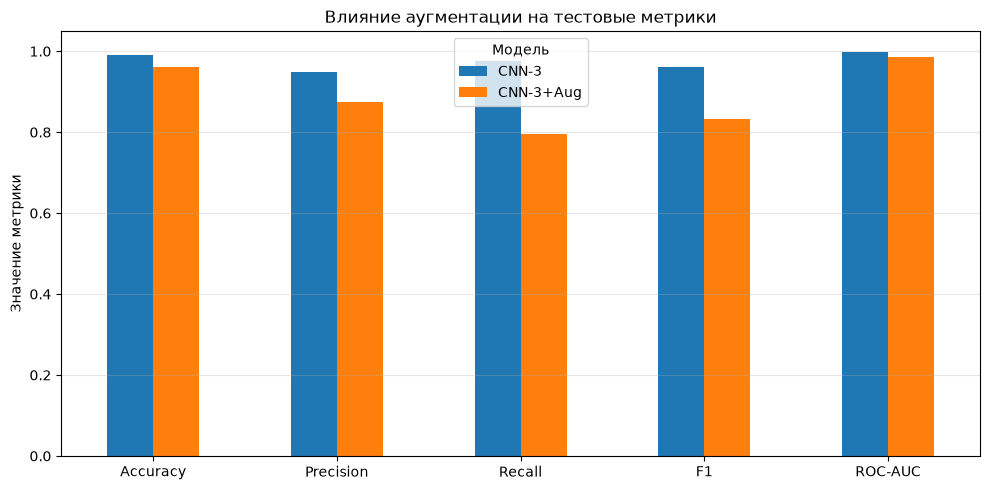

In [42]:
test_aug_results = []

for name in [best_base, aug_name]:
    if name == best_bin_name:
        y_prob = bin_test_prob
    else:
        model = models.load_model(
            ARTIFACTS_DIR / f"{name}_best.keras"
        )
        y_prob = model.predict(test_ds_bin, verbose=0).ravel()
        del model

    y_pred = (y_prob >= 0.5).astype(int)

    test_aug_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test_bin, y_pred),
        "Precision": precision_score(y_test_bin, y_pred, zero_division=0),
        "Recall": recall_score(y_test_bin, y_pred, zero_division=0),
        "F1": f1_score(y_test_bin, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_bin, y_prob)
    })

    tf.keras.backend.clear_session()
    gc.collect()

test_aug_df = pd.DataFrame(test_aug_results)

print(test_aug_df.round(4).to_string(index=False))

test_aug_df.to_csv(
    ARTIFACTS_DIR / "augmentation_test_comparison.csv",
    index=False
)

test_aug_df.set_index('Модель')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].T.plot(kind='bar', figsize=(10, 5), rot=0)
plt.title('Влияние аугментации на тестовые метрики')
plt.ylabel('Значение метрики')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / 'augmentation_test_comparison.png', dpi=150)
plt.show()

In [43]:
from IPython.display import Markdown, display
r = results_all_df.set_index('Эксперимент')
lines = ['## Итоги фактически выполненных экспериментов']
for a, b, subject in [('CNN-1','CNN-2','Глубина, GAP и удаление Dropout'), ('CNN-2','CNN-3','BatchNormalization'), ('CNN-3','CNN-3+Dropout','Dropout'), ('CNN-3','CNN-3+SGD','Замена Adam на SGD'), (best_base,aug_name,'Аугментация')]:
    x, y = r.loc[a], r.loc[b]
    lines.append(f'- **{subject}:** {a} → {b}; Val F1 {x["Val F1"]:.4f} → {y["Val F1"]:.4f}; Val Loss {x["Val Loss"]:.4f} → {y["Val Loss"]:.4f}; параметры {x["Параметры"]:,} → {y["Параметры"]:,}.')
lines.append(f'- Разрыв Train − Validation Accuracy на лучшей по Loss эпохе: без аугментации {gap_before:+.4f}, с аугментацией {gap_after:+.4f}. Train Accuracy с аугментацией измеряется на изменённых изображениях, поэтому разрывы не полностью сопоставимы.')
aug_test = test_aug_df.set_index('Модель')['F1']
lines.append(f'- Test F1 до/после аугментации: {aug_test[best_base]:.4f} → {aug_test[aug_name]:.4f}.')
lines.append(f'- Лучшая по Validation модель: **{best_bin_name}**. Test F1 = {best_binary_test_df.iloc[0]["F1-score"]:.4f}, ROC-AUC = {best_binary_test_df.iloc[0]["ROC-AUC"]:.4f}.')
report = '\n\n'.join(lines)
display(Markdown(report))
(ARTIFACTS_DIR / 'conclusions.md').write_text(report, encoding='utf-8')

## Итоги фактически выполненных экспериментов

- **Глубина, GAP и удаление Dropout:** CNN-1 → CNN-2; Val F1 0.8712 → 0.8057; Val Loss 0.1218 → 0.1136; параметры 25,709,761 → 109,889.

- **BatchNormalization:** CNN-2 → CNN-3; Val F1 0.8057 → 0.9665; Val Loss 0.1136 → 0.0274; параметры 109,889 → 110,945.

- **Dropout:** CNN-3 → CNN-3+Dropout; Val F1 0.9665 → 0.9212; Val Loss 0.0274 → 0.0482; параметры 110,945 → 110,945.

- **Замена Adam на SGD:** CNN-3 → CNN-3+SGD; Val F1 0.9665 → 0.8237; Val Loss 0.0274 → 0.0919; параметры 110,945 → 110,945.

- **Аугментация:** CNN-3 → CNN-3+Aug; Val F1 0.9665 → 0.8311; Val Loss 0.0274 → 0.1099; параметры 110,945 → 110,945.

- Разрыв Train − Validation Accuracy на лучшей по Loss эпохе: без аугментации -0.0048, с аугментацией +0.0167. Train Accuracy с аугментацией измеряется на изменённых изображениях, поэтому разрывы не полностью сопоставимы.

- Test F1 до/после аугментации: 0.9618 → 0.8331.

- Лучшая по Validation модель: **CNN-3**. Test F1 = 0.9618, ROC-AUC = 0.9989.

1016

## Вывод по бинарной классификации

В ходе выполнения первой части лабораторной работы
был исследован набор изображений PlantVillage,
содержащий изображения листьев растений трёх классов:
Tomato, Potato и Pepper.

Была выполнена предварительная обработка данных,
включающая проверку повреждённых изображений, удаление
точных дубликатов, анализ распределения классов,
приведение изображений к размеру 224 × 224 пикселя,
преобразование в RGB-формат и нормализацию значений
пикселей в диапазон [0; 1].

Данные были разделены на обучающую, валидационную
и тестовую выборки в соотношении 70/15/15
с использованием стратификации. Для компенсации
дисбаланса классов были рассчитаны веса классов
на основании обучающей выборки.

### Исследование архитектур CNN

В ходе экспериментов были построены и обучены шесть
вариантов свёрточных нейронных сетей.

| Модель | Val Accuracy | Val F1 | Val Loss |
|---|---:|---:|---:|
| CNN-1 | 0.9680 | 0.8630 | 0.1017 |
| CNN-2 | 0.9754 | 0.8989 | 0.0728 |
| CNN-3 | 0.9945 | 0.9771 | 0.0192 |
| CNN-3+Aug | 0.9247 | 0.5648 | 0.1682 |
| CNN-3+Dropout | 0.9603 | 0.8457 | 0.0962 |
| CNN-3+SGD | 0.9893 | 0.9553 | 0.0378 |

Переход от CNN-1 к CNN-2 позволил повысить качество
классификации. Увеличение глубины сети и количества
фильтров обеспечило возможность извлечения более
сложных пространственных признаков.

Замена слоя Flatten на GlobalAveragePooling2D
позволила значительно уменьшить количество параметров
модели и снизить вычислительную сложность
полносвязной части сети.

Наилучшие результаты показала модель CNN-3,
использующая три свёрточных блока и BatchNormalization.
Применение BatchNormalization способствовало
стабилизации процесса обучения.

### Исследование влияния Dropout

Добавление Dropout со значением 0.5 к архитектуре CNN-3
привело к снижению Accuracy на валидационной выборке
с 0.9945 до 0.9603, а F1-score — с 0.9771 до 0.8457.

Можно предположить, что выбранное значение Dropout
оказалось слишком высоким для рассматриваемой
архитектуры и ограничило способность сети
извлекать значимые признаки.

Таким образом, дополнительная регуляризация
в данном эксперименте не обеспечила повышения
качества классификации.

### Исследование влияния оптимизатора

Для архитектуры CNN-3 было проведено сравнение
оптимизаторов Adam и SGD с Momentum.

При использовании Adam значение F1-score
на валидационной выборке составило 0.9771,
а при использовании SGD — 0.9553.

Оба оптимизатора обеспечили высокое качество
классификации, однако Adam показал лучшие результаты
при выбранных параметрах обучения.

Это может объясняться способностью Adam адаптивно
изменять скорость обновления отдельных параметров сети.

### Исследование влияния аугментации

Для исследования влияния аугментации были использованы
случайные горизонтальные отражения, повороты,
масштабирование и сдвиги изображений.

Аугментация применялась исключительно к обучающей
выборке.

| Метрика Test | Без аугментации | С аугментацией |
|---|---:|---:|
| Accuracy | 0.9945 | 0.9254 |
| Precision | 0.9695 | 0.9167 |
| Recall | 0.9845 | 0.4087 |
| F1-score | 0.9770 | 0.5653 |
| ROC-AUC | 0.9996 | 0.9640 |

В данном эксперименте применение аугментации
привело к снижению качества классификации.

Особенно значительно уменьшилось значение Recall,
что свидетельствует об увеличении количества
пропущенных объектов положительного класса Potato.

Возможной причиной является чрезмерное изменение
пространственных характеристик изображений при
выбранных параметрах аугментации.

Таким образом, выбранная конфигурация аугментации
не обеспечила улучшения обобщающей способности модели.

### Выбор лучшей модели

Выбор лучшей модели осуществлялся исключительно
на основании результатов валидационной выборки
по максимальному значению F1-score с учётом Val Loss.

Лучшей моделью была выбрана CNN-3.

На отложенной тестовой выборке были получены
следующие результаты:

| Метрика | Значение |
|---|---:|
| Accuracy | 0.9945 |
| Precision | 0.9695 |
| Recall | 0.9845 |
| F1-score | 0.9770 |
| ROC-AUC | 0.9996 |

Положительным классом является Potato (метка 1).

Полученные значения свидетельствуют о высокой
способности модели различать изображения двух классов.

### Общий вывод

В результате выполнения первой части лабораторной
работы были получены практические навыки построения,
обучения и оценки свёрточных нейронных сетей.

Было исследовано влияние глубины сети, количества
фильтров, BatchNormalization, Dropout, оптимизатора
и аугментации на качество классификации.

Наиболее эффективной в проведённых экспериментах
оказалась архитектура CNN-3 с BatchNormalization
и оптимизатором Adam без дополнительного Dropout
и аугментации.

Лучшая модель была сохранена для дальнейшего
использования.